# S25 - Módulo 2. Actividad didáctica 2
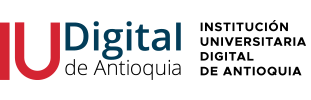
# Ingeniería de Software y Datos · IU Digital de Antioquia

Grupo:	45

Integrantes:	Jose Hilario Lopez / Dennyn Pandales

Facultad:	Ingeniería y Ciencias Agrícolas

Programa:	Ingeniería de Software y Datos

Asignatura:	Simulación - PREICA2602B020045

Catedràtico: Julian Andres Loaiza

Fecha de entrega	domingo 15 de Noviembre

In [1]:
# ==============================================================================
# ARCHIVO 1: src/hmm_core.py
# Núcleo matemático del Modelo Oculto de Markov (Discreto y Continuo Gaussiano)
# Implementa: Simulación, Forward (Log-Likelihood), Viterbi y Baum-Welch (EM)
# ==============================================================================
import numpy as np
from scipy.stats import norm
from scipy.special import logsumexp


class SupplyChainHMM:
    """
    Modelo Oculto de Markov (HMM) para inferencia de resiliencia en cadenas
    de suministro. Soporta emisiones discretas (Categóricas) y continuas (Gaussianas).
    """

    def __init__(self, A, pi, emission_type="discrete", B=None, means=None, stds=None):
        self.A = np.asarray(A, dtype=float)
        self.pi = np.asarray(pi, dtype=float)
        self.N = self.A.shape[0]
        self.emission_type = emission_type

        if emission_type == "discrete":
            self.B = np.asarray(B, dtype=float)
            self.M = self.B.shape[1]
        elif emission_type == "gaussian":
            self.means = np.asarray(means, dtype=float)
            self.stds = np.asarray(stds, dtype=float)
        else:
            raise ValueError("emission_type debe ser 'discrete' o 'gaussian'.")

    def _compute_log_emission_matrix(self, obs):
        """Calcula log P(O_t | S_t = j) para todo t y todo estado j."""
        T = len(obs)
        eps = 1e-300
        log_B_obs = np.zeros((T, self.N))

        if self.emission_type == "discrete":
            log_B = np.log(np.clip(self.B, eps, 1.0))
            for t in range(T):
                log_B_obs[t, :] = log_B[:, int(obs[t])]
        else:
            for j in range(self.N):
                log_B_obs[:, j] = norm.logpdf(obs, loc=self.means[j], scale=self.stds[j])

        return log_B_obs

    def sample(self, T, rng):
        """Genera una trayectoria de estados ocultos y observaciones usando rng."""
        states = np.zeros(T, dtype=int)
        obs = np.zeros(T, dtype=int if self.emission_type == "discrete" else float)

        states[0] = rng.choice(self.N, p=self.pi)
        for t in range(T):
            if t > 0:
                states[t] = rng.choice(self.N, p=self.A[states[t - 1]])
            s_t = states[t]
            if self.emission_type == "discrete":
                obs[t] = rng.choice(self.M, p=self.B[s_t])
            else:
                obs[t] = rng.normal(loc=self.means[s_t], scale=self.stds[s_t])

        return states, obs

    def forward_log(self, obs):
        """Algoritmo Forward en espacio logarítmico. Retorna log P(O | lambda) y log_alpha."""
        T = len(obs)
        eps = 1e-300
        log_A = np.log(np.clip(self.A, eps, 1.0))
        log_pi = np.log(np.clip(self.pi, eps, 1.0))
        log_B_obs = self._compute_log_emission_matrix(obs)

        log_alpha = np.zeros((T, self.N))
        log_alpha[0, :] = log_pi + log_B_obs[0, :]

        for t in range(1, T):
            for j in range(self.N):
                log_alpha[t, j] = logsumexp(log_alpha[t - 1, :] + log_A[:, j]) + log_B_obs[t, j]

        log_likelihood = float(logsumexp(log_alpha[T - 1, :]))
        return log_likelihood, log_alpha

    def backward_log(self, obs):
        """Algoritmo Backward en espacio logarítmico (apoyo para Baum-Welch)."""
        T = len(obs)
        eps = 1e-300
        log_A = np.log(np.clip(self.A, eps, 1.0))
        log_B_obs = self._compute_log_emission_matrix(obs)

        log_beta = np.zeros((T, self.N))
        for t in range(T - 2, -1, -1):
            for i in range(self.N):
                log_beta[t, i] = logsumexp(log_A[i, :] + log_B_obs[t + 1, :] + log_beta[t + 1, :])

        return log_beta

    def viterbi_decode(self, obs):
        """Algoritmo de Viterbi en espacio logarítmico."""
        T = len(obs)
        eps = 1e-300
        log_A = np.log(np.clip(self.A, eps, 1.0))
        log_pi = np.log(np.clip(self.pi, eps, 1.0))
        log_B_obs = self._compute_log_emission_matrix(obs)

        delta = np.zeros((T, self.N))
        psi = np.zeros((T, self.N), dtype=int)

        delta[0, :] = log_pi + log_B_obs[0, :]

        for t in range(1, T):
            for j in range(self.N):
                scores = delta[t - 1, :] + log_A[:, j]
                psi[t, j] = np.argmax(scores)
                delta[t, j] = scores[psi[t, j]] + log_B_obs[t, j]

        q_star = np.zeros(T, dtype=int)
        q_star[T - 1] = np.argmax(delta[T - 1, :])
        for t in range(T - 2, -1, -1):
            q_star[t] = psi[t + 1, q_star[t + 1]]

        return q_star, float(np.max(delta[T - 1, :]))

    def baum_welch_fit(self, sequences, n_iter=25, tol=1e-4):
        """
        Algoritmo Baum-Welch (EM) para reestimar A, B y pi desde secuencias discretas.
        """
        if self.emission_type != "discrete":
            raise NotImplementedError("Baum-Welch implementado para emisiones discretas.")

        history_ll = []
        eps = 1e-12

        for _ in range(n_iter):
            pi_acc = np.zeros(self.N) + eps
            A_num = np.zeros((self.N, self.N)) + eps
            A_den = np.zeros((self.N, 1)) + eps
            B_num = np.zeros((self.N, self.M)) + eps
            B_den = np.zeros((self.N, 1)) + eps
            total_ll = 0.0

            log_A = np.log(np.clip(self.A, 1e-300, 1.0))

            for obs in sequences:
                T = len(obs)
                ll, log_alpha = self.forward_log(obs)
                log_beta = self.backward_log(obs)
                log_B_obs = self._compute_log_emission_matrix(obs)
                total_ll += ll

                # Gamma: P(S_t = i | O, lambda)
                log_gamma = log_alpha + log_beta
                log_gamma -= logsumexp(log_gamma, axis=1, keepdims=True)
                gamma = np.exp(log_gamma)

                pi_acc += gamma[0, :]
                B_den += np.sum(gamma, axis=0, keepdims=True).T
                for k in range(self.M):
                    mask = (obs == k)
                    if np.any(mask):
                        B_num[:, k] += np.sum(gamma[mask, :], axis=0)

                # Xi: P(S_t = i, S_{t+1} = j | O, lambda)
                for t in range(T - 1):
                    log_xi = (
                        log_alpha[t, :, None]
                        + log_A
                        + log_B_obs[t + 1, None, :]
                        + log_beta[t + 1, None, :]
                    )
                    log_xi -= logsumexp(log_xi)
                    xi = np.exp(log_xi)
                    A_num += xi
                    A_den += np.sum(xi, axis=1, keepdims=True)

            self.pi = pi_acc / np.sum(pi_acc)
            self.A = A_num / A_den
            self.B = B_num / B_den

            history_ll.append(total_ll)
            if len(history_ll) > 1 and abs(history_ll[-1] - history_ll[-2]) < tol:
                break

        return history_ll


# ==============================================================================
# ARCHIVO 2: src/utils_stats.py
# Cálculo de estadísticos descriptivos, IC 95%, Baseline y Matriz de Confusión
# ==============================================================================
import pandas as pd


def baseline_threshold_predict(obs, emission_type="discrete"):
    """Clasificador de referencia (Baseline) sin memoria secuencial."""
    if emission_type == "discrete":
        return np.asarray(obs, dtype=int)
    else:
        preds = np.zeros(len(obs), dtype=int)
        preds[(obs > 3.2) & (obs <= 6.8)] = 1
        preds[obs > 6.8] = 2
        return preds


def compute_summary_stats(values, label):
    """Calcula Media, Desv. Estándar, Mínimo, Máximo e IC 95%."""
    arr = np.asarray(values, dtype=float)
    n = len(arr)
    mean = float(np.mean(arr))
    std = float(np.std(arr, ddof=1))
    se = std / np.sqrt(n)
    ci_low = mean - 1.96 * se
    ci_high = mean + 1.96 * se
    return {
        "Escenario / Modelo": label,
        "Media": round(mean, 4),
        "Desv_Std": round(std, 4),
        "Minimo": round(float(np.min(arr)), 4),
        "Maximo": round(float(np.max(arr)), 4),
        "IC95_Inf": round(ci_low, 4),
        "IC95_Sup": round(ci_high, 4),
        "IC_95_Texto": f"[{ci_low:.4f}, {ci_high:.4f}]",
    }


def compute_confusion_matrix(y_true, y_pred, n_classes=3):
    """Calcula matriz de confusión normalizada por filas."""
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    return cm, cm_norm


# ==============================================================================
# ARCHIVO 3: main_simulation.py
# Script principal reproducible (seed=42, N=100 réplicas, T=60 pasos)
# Genera CSVs de resultados y 3 figuras de calidad publicable (300 dpi, fondo blanco)
# ==============================================================================
import matplotlib.pyplot as plt

# Configuración global de estilo limpio para publicación científica (300 dpi)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
})


def run_experiments(seed=42, n_reps=100, T=60):
    rng = np.random.default_rng(seed)

    pi_common = np.array([0.75, 0.20, 0.05])

    # Escenario 1: Nominal Estable
    A_e1 = np.array([
        [0.85, 0.12, 0.03],
        [0.25, 0.60, 0.15],
        [0.10, 0.30, 0.60],
    ])
    B_e1 = np.array([
        [0.80, 0.15, 0.05],
        [0.20, 0.60, 0.20],
        [0.05, 0.25, 0.70],
    ])

    # Escenario 2: Alta Perturbación Logística
    A_e2 = np.array([
        [0.55, 0.30, 0.15],
        [0.20, 0.50, 0.30],
        [0.10, 0.35, 0.55],
    ])
    B_e2 = np.array([
        [0.65, 0.25, 0.10],
        [0.25, 0.45, 0.30],
        [0.10, 0.35, 0.55],
    ])

    # Escenario 3: Emisiones Continuas Gaussianas (Lead Time en días)
    means_e3 = np.array([2.0, 4.8, 9.5])
    stds_e3 = np.array([0.6, 1.1, 2.2])

    scenarios = {
        "E1: Nominal": SupplyChainHMM(A_e1, pi_common, "discrete", B=B_e1),
        "E2: Perturbado": SupplyChainHMM(A_e2, pi_common, "discrete", B=B_e2),
        "E3: Gaussiano": SupplyChainHMM(A_e1, pi_common, "gaussian", means=means_e3, stds=stds_e3),
    }

    results_hmm = {k: [] for k in scenarios}
    results_base = {k: [] for k in scenarios}
    log_likelihoods = {k: [] for k in scenarios}
    all_true = {k: [] for k in scenarios}
    all_pred = {k: [] for k in scenarios}
    e1_sequences = []
    sample_trajectory = None

    for name, model in scenarios.items():
        for rep in range(n_reps):
            states, obs = model.sample(T, rng)
            pred_hmm, _ = model.viterbi_decode(obs)
            pred_base = baseline_threshold_predict(obs, model.emission_type)
            ll, _ = model.forward_log(obs)

            acc_hmm = np.mean(pred_hmm == states)
            acc_base = np.mean(pred_base == states)

            results_hmm[name].append(acc_hmm)
            results_base[name].append(acc_base)
            log_likelihoods[name].append(ll)
            all_true[name].extend(states)
            all_pred[name].extend(pred_hmm)

            if name == "E1: Nominal":
                e1_sequences.append(obs)
                if rep == 0:
                    sample_trajectory = (states, obs, pred_hmm, pred_base)

    # Tabla resumen de métricas
    summary_rows = []
    for name in scenarios:
        summary_rows.append(compute_summary_stats(results_hmm[name], f"{name} (HMM Viterbi)"))
        summary_rows.append(compute_summary_stats(results_base[name], f"{name} (Baseline Umbral)"))

    df_summary = pd.DataFrame(summary_rows)
    df_summary.to_csv("resultados_estadisticos_hmm.csv", index=False)
    print("\n=== TABLA RESUMEN DE RESULTADOS (N=100, T=60, seed=42) ===")
    print(df_summary[["Escenario / Modelo", "Media", "Desv_Std", "Minimo", "Maximo", "IC_95_Texto"]].to_string(index=False))

    # Prueba de aprendizaje no supervisado (Baum-Welch) sobre E1
    rng_bw = np.random.default_rng(seed)
    A_init = np.array([[0.6, 0.25, 0.15], [0.25, 0.5, 0.25], [0.15, 0.35, 0.5]])
    B_init = np.array([[0.6, 0.3, 0.1], [0.3, 0.4, 0.3], [0.1, 0.3, 0.6]])
    bw_model = SupplyChainHMM(A_init, np.array([0.5, 0.3, 0.2]), "discrete", B=B_init)
    ll_curve = bw_model.baum_welch_fit(e1_sequences[:30], n_iter=20)
    print("\n=== CONVERGENCIA BAUM-WELCH (Log-Verosimilitud) ===")
    print(f"Iteración 1: {ll_curve[0]:.2f} -> Iteración Final ({len(ll_curve)}): {ll_curve[-1]:.2f}")
    print("Matriz A estimada por Baum-Welch:\n", np.round(bw_model.A, 3))

    # --------------------------------------------------------------------------
    # FIGURA 1: Comparación de Exactitud e IC 95% (HMM Viterbi vs Baseline)
    # --------------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=300)
    labels = list(scenarios.keys())
    x = np.arange(len(labels))
    width = 0.35

    hmm_means = [np.mean(results_hmm[k]) for k in labels]
    hmm_cis = [1.96 * np.std(results_hmm[k], ddof=1) / np.sqrt(n_reps) for k in labels]
    base_means = [np.mean(results_base[k]) for k in labels]
    base_cis = [1.96 * np.std(results_base[k], ddof=1) / np.sqrt(n_reps) for k in labels]

    rects1 = ax.bar(x - width / 2, hmm_means, width, yerr=hmm_cis, capsize=5,
                    label="HMM (Decodificación Viterbi)", color="#1f4e78", edgecolor="black")
    rects2 = ax.bar(x + width / 2, base_means, width, yerr=base_cis, capsize=5,
                    label="Baseline (Umbral sin memoria)", color="#a6a6a6", edgecolor="black")

    ax.set_ylabel("Exactitud de Decodificación")
    ax.set_title("Comparación de Exactitud Media e IC 95% por Escenario (N = 100)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0.50, 1.05)
    ax.legend(loc="lower left", frameon=True)

    for rect in rects1:
        h = rect.get_height()
        ax.annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width() / 2, h + 0.015),
                    ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    for rect in rects2:
        h = rect.get_height()
        ax.annotate(f"{h:.3f}", xy=(rect.get_x() + rect.get_width() / 2, h + 0.015),
                    ha="center", va="bottom", fontsize=8.5)

    plt.tight_layout()
    plt.savefig("fig1_comparacion_escenarios.png", dpi=300)
    plt.close()

    # --------------------------------------------------------------------------
    # FIGURA 2: Trayectoria Temporal de Inferencia de Estados (Réplica 1 - E1)
    # --------------------------------------------------------------------------
    states_s, obs_s, pred_hmm_s, pred_base_s = sample_trajectory
    dias = np.arange(1, T + 1)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.5, 5.2), dpi=300, sharex=True)

    ax1.step(dias, obs_s, where="mid", color="#2e75b6", linewidth=1.6, label="Observación Lead Time (0:Corto, 1:Medio, 2:Largo)")
    ax1.set_yticks([0, 1, 2])
    ax1.set_yticklabels(["Corto (v1)", "Medio (v2)", "Largo (v3)"])
    ax1.set_ylabel("Señal Observada")
    ax1.set_title("Secuencia Observada vs. Inferencia de Estados Ocultos (Escenario Nominal, T=60)")
    ax1.legend(loc="upper right")

    ax2.step(dias, states_s, where="mid", color="black", linewidth=2.0, label="Estado Oculto Real")
    ax2.step(dias, pred_hmm_s, where="mid", color="#c00000", linestyle="--", linewidth=1.6, label="Inferencia HMM (Viterbi)")
    ax2.set_yticks([0, 1, 2])
    ax2.set_yticklabels(["Normal (s1)", "Retraso (s2)", "Colapso (s3)"])
    ax2.set_xlabel("Día de Operación Logística (t)")
    ax2.set_ylabel("Estado Operativo")
    ax2.legend(loc="upper right")

    plt.tight_layout()
    plt.savefig("fig2_trayectoria_viterbi.png", dpi=300)
    plt.close()

    # --------------------------------------------------------------------------
    # FIGURA 3: Matrices de Confusión Normalizadas (E1 Nominal vs E2 Perturbado)
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.0), dpi=300)
    state_names = ["Normal", "Retraso", "Colapso"]

    for idx, sc_name in enumerate(["E1: Nominal", "E2: Perturbado"]):
        _, cm_norm = compute_confusion_matrix(all_true[sc_name], all_pred[sc_name])
        im = axes[idx].imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
        axes[idx].set_title(f"Matriz de Confusión - {sc_name}")
        axes[idx].set_xticks([0, 1, 2])
        axes[idx].set_yticks([0, 1, 2])
        axes[idx].set_xticklabels(state_names)
        axes[idx].set_yticklabels(state_names)
        axes[idx].set_xlabel("Estado Inferido (Viterbi)")
        if idx == 0:
            axes[idx].set_ylabel("Estado Oculto Real")

        for i in range(3):
            for j in range(3):
                color = "white" if cm_norm[i, j] > 0.55 else "black"
                axes[idx].text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", color=color, fontweight="bold")

    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.82, label="Proporción de Clasificación")
    plt.savefig("fig3_matrices_confusion.png", dpi=300, bbox_inches="tight")
    plt.close()

    print("\nArchivos generados exitosamente:")
    print("- resultados_estadisticos_hmm.csv")
    print("- fig1_comparacion_escenarios.png")
    print("- fig2_trayectoria_viterbi.png")
    print("- fig3_matrices_confusion.png")


if __name__ == "__main__":
    run_experiments(seed=42, n_reps=100, T=60)


=== TABLA RESUMEN DE RESULTADOS (N=100, T=60, seed=42) ===
              Escenario / Modelo  Media  Desv_Std  Minimo  Maximo      IC_95_Texto
       E1: Nominal (HMM Viterbi) 0.7817    0.0884  0.5167  0.9667 [0.7643, 0.7990]
   E1: Nominal (Baseline Umbral) 0.7350    0.0635  0.5833  0.8833 [0.7226, 0.7474]
    E2: Perturbado (HMM Viterbi) 0.5223    0.0756  0.3167  0.6833 [0.5075, 0.5371]
E2: Perturbado (Baseline Umbral) 0.5277    0.0632  0.4167  0.6667 [0.5153, 0.5401]
     E3: Gaussiano (HMM Viterbi) 0.9590    0.0309  0.8333  1.0000 [0.9529, 0.9651]
 E3: Gaussiano (Baseline Umbral) 0.9417    0.0349  0.8333  1.0000 [0.9348, 0.9485]

=== CONVERGENCIA BAUM-WELCH (Log-Verosimilitud) ===
Iteración 1: -1877.25 -> Iteración Final (20): -1734.90
Matriz A estimada por Baum-Welch:
 [[0.772 0.179 0.049]
 [0.242 0.475 0.284]
 [0.155 0.268 0.578]]

Archivos generados exitosamente:
- resultados_estadisticos_hmm.csv
- fig1_comparacion_escenarios.png
- fig2_trayectoria_viterbi.png
- fig3_matrices_co